# 08 — Final Model Comparison

**Music Genre Classification Using Audio Signal Processing and Deep Learning**

This notebook consolidates the already-recorded results from the team's CNN and classical machine-learning experiments. It does **not** retrain models.

## Dataset and evaluation
- Dataset: GTZAN, 1,000 audio tracks across 10 genres
- Shared split: 700 training, 150 validation, 150 test tracks
- Classical models use 137 handcrafted audio features.
- CNN uses 2-second log-mel spectrogram segments.

## Important interpretation note
The results below come from the team's saved notebook outputs. The CNN and classical final pipelines differ in training procedure: the classical best-model notebook retrains on train + validation (850 samples), while the CNN best-model run trains on 700 samples and selects a checkpoint using validation accuracy. Therefore, this is a practical project comparison, not a perfectly controlled architecture-only comparison. Do not claim the differences are caused solely by model type.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Final model comparison — using saved experiment results only.")

Final model comparison — using saved experiment results only.


## 1. Recorded final test results

Values below were taken from the saved outputs of `06_Best_CNN.ipynb`, `07_Best_Classical_Model.ipynb`, and `04_Classical_ML.ipynb`. The Random Forest entry is the classical baseline final-test result; the SVM entry is the tuned classical final-test result.

In [2]:
results = pd.DataFrame([
    {
        "Model": "CNN (log-mel)",
        "Experiment": "Final CNN",
        "Test Accuracy": 0.5667,
        "Test Macro-F1": 0.5443,
        "Validation Metric": "Accuracy",
        "Validation Score": 0.5867,
        "Training Samples": 700
    },
    {
        "Model": "SVM (137 handcrafted features)",
        "Experiment": "Tuned classical model",
        "Test Accuracy": 0.7200,
        "Test Macro-F1": 0.7183,
        "Validation Metric": "Macro-F1",
        "Validation Score": 0.7974,
        "Training Samples": 850
    },
    {
        "Model": "Random Forest (137 handcrafted features)",
        "Experiment": "Classical baseline best",
        "Test Accuracy": 0.7467,
        "Test Macro-F1": 0.7377,
        "Validation Metric": "Macro-F1",
        "Validation Score": 0.7855,
        "Training Samples": 850
    }
])

display(results)
print("\nNote: validation scores use different metrics for CNN vs classical models; compare them only with that distinction in mind.")

,Model,Experiment,Test Accuracy,Test Macro-F1,Validation Metric,Validation Score,Training Samples
0,CNN (log-mel),Final CNN,0.5667,0.5443,Accuracy,0.5867,700
1,SVM (137 handcrafted features),Tuned classical model,0.7200,0.7183,Macro-F1,0.7974,850
2,Random Forest (137 handcrafted features),Classical baseline best,0.7467,0.7377,Macro-F1,0.7855,850



Note: validation scores use different metrics for CNN vs classical models; compare them only with that distinction in mind.


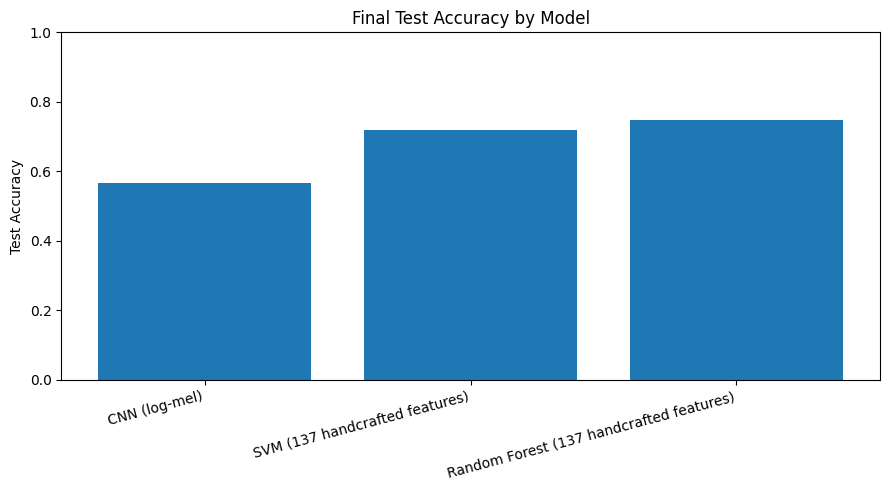

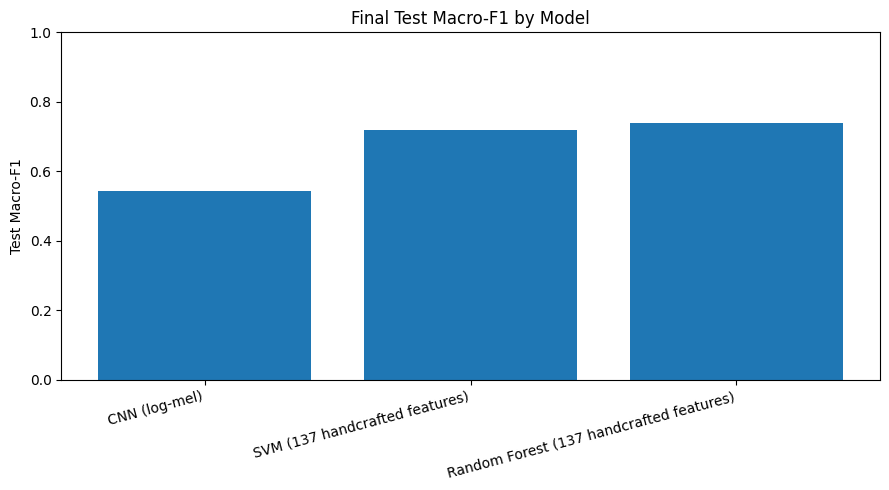

In [3]:
# Test accuracy comparison
plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["Test Accuracy"])
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.title("Final Test Accuracy by Model")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# Test Macro-F1 comparison
plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["Test Macro-F1"])
plt.ylabel("Test Macro-F1")
plt.ylim(0, 1)
plt.title("Final Test Macro-F1 by Model")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 2. What the results suggest

- The recorded Random Forest baseline has the highest test accuracy (**74.67%**) and test Macro-F1 (**0.7377**) among these three entries.
- The tuned SVM reaches **72.00% test accuracy** and **0.7183 test Macro-F1**.
- The CNN reaches **56.67% test accuracy** and **0.5443 test Macro-F1** using 2-second log-mel segments.
- In the classical feature-ablation experiment, the full 137-feature configuration had the best validation Macro-F1 (**0.7974**), compared with the smaller feature groups tested.

These results suggest the handcrafted feature pipeline was more effective in the current experiments than the short-segment CNN pipeline. However, the comparison is not a controlled proof that classical models are inherently better: the training sizes and training procedures differ.

,Feature Configuration,Feature Count,Validation Macro-F1
0,MFCC,26,0.5949
1,MFCC + Delta,52,0.6193
2,MFCC + Delta + Delta2,78,0.6505
3,+ Chroma,102,0.6771
4,+ Spectral,132,0.7650
5,All features,137,0.7974


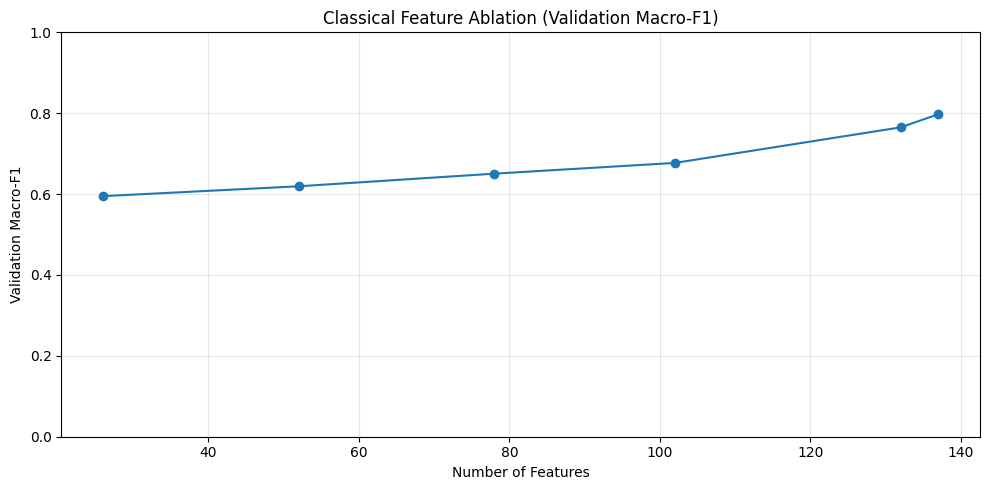

In [4]:
# Feature ablation results recorded in 06_Feature_Ablation.ipynb (validation results)
feature_ablation = pd.DataFrame([
    ["MFCC", 26, 0.5949],
    ["MFCC + Delta", 52, 0.6193],
    ["MFCC + Delta + Delta2", 78, 0.6505],
    ["+ Chroma", 102, 0.6771],
    ["+ Spectral", 132, 0.7650],
    ["All features", 137, 0.7974],
], columns=["Feature Configuration", "Feature Count", "Validation Macro-F1"])

display(feature_ablation)

plt.figure(figsize=(10, 5))
plt.plot(feature_ablation["Feature Count"], feature_ablation["Validation Macro-F1"], marker="o")
plt.xlabel("Number of Features")
plt.ylabel("Validation Macro-F1")
plt.ylim(0, 1)
plt.title("Classical Feature Ablation (Validation Macro-F1)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. CNN error analysis

The final CNN confusion matrix showed substantial variation by genre:
- Classical: 14/15 correct (93.33% recall)
- Hip-hop: 13/15 correct (86.67% recall)
- Metal: 13/15 correct (86.67% recall)
- Jazz: 5/15 correct (33.33% recall)
- Rock: 2/15 correct (13.33% recall)

The CNN most often struggled with rock and jazz in this test run. This may reflect the limited context in two-second segments and overlapping acoustic patterns between genres. These observations describe this test split and should not be generalized beyond it.

## 4. Limitations and reproducibility notes

1. The CNN tuning notebook reports test metrics for multiple configurations. For strict methodology, tuning should use validation data only; treat those per-configuration test results as exploratory and do not use them to claim a test-set tuning improvement.
2. The CNN final run logs an audio decoding warning for one jazz clip. This should be disclosed and the handling should be checked if the experiment is rerun.
3. The CNN and classical final models use different training sample counts (700 vs 850), so the comparison is not perfectly controlled.
4. The project's current `README.md` and `requirements.txt` were empty in the inspected ZIP. Fill these before final submission with setup instructions and dependencies.
5. The notebook outputs are the recorded results; this notebook does not retrain models or independently verify the saved models.

## 5. Conclusion

For the experiments completed so far, the classical models using handcrafted audio features outperform the current CNN on the held-out test metrics. The best recorded classical baseline is Random Forest at **74.67% accuracy / 0.7377 Macro-F1**, while the tuned SVM reaches **72.00% / 0.7183**. The final CNN reaches **56.67% / 0.5443**.

The project demonstrates two complementary approaches: handcrafted signal features with classical classifiers, and log-mel spectrograms with a CNN. A future controlled experiment could equalize training data and selection protocols, improve handling of audio-decoding failures, and evaluate longer audio context.

In [5]:
# Save the combined table for the report/repository
results.to_csv("final_model_comparison.csv", index=False)
feature_ablation.to_csv("feature_ablation_summary.csv", index=False)

print("Saved: final_model_comparison.csv")
print("Saved: feature_ablation_summary.csv")
print("\nFINAL MODEL COMPARISON COMPLETE")

Saved: final_model_comparison.csv
Saved: feature_ablation_summary.csv

FINAL MODEL COMPARISON COMPLETE
